# Mobile-device LiDAR point clouds of horticultural crops: HSV segmentation reproduction

Reproduction of the central segmentation analysis of
**"Proximal sensing of horticultural crops with mobile device LiDAR"**
(Smart Agricultural Technology 13:101799, 2026; DOI [10.1016/j.atech.2026.101799](https://doi.org/10.1016/j.atech.2026.101799)),
by Steven A. Doyle, Ankita Raturi, Elizabeth T. Maynard, Petrus Langenhoven, and Wenjing Guan (Purdue University).

**What this notebook does (executed scope):** re-runs the paper's HSV-thresholding point-cloud segmentation
pipeline (`processing_pipeline.ipynb` + `pfunctions.py` from the author repository
[`ag-informatics/hort-lidar-processing`](https://github.com/ag-informatics/hort-lidar-processing), pinned commit
`68cbef58077faaa9933fc8c2fb75f6124abbb164`) on the five `Transplant-Age_Plants` colorized LiDAR point clouds of the
public PURR dataset ["Horticultural Crop Point Clouds" v2](https://doi.org/10.4231/T8QZ-9D83) (CC BY 4.0, 519 MB trial bundle).
It then (a) compares our recomputed clouds point-by-point with the authors' released processed clouds,
(b) evaluates segmentation against the authors' released ground-truth annotations with their IoU protocol,
and (c) computes sensed plant height as in `sensor_validation_pipeline.ipynb`.

**What is NOT done (out of scope):** whole-dataset processing (295 clouds), the paper-wide mIoU benchmark,
volume/biomass regressions, and the physical-height validation statistics (those use the Tomato_Fertilizer and
Garden_Plots trials, whose 5–9 GB bundles are not downloaded here).

**Execution status:** CPU-only; no GPU and no trained model are involved. Expected end-to-end "Run all" time ≈ 10–15 min
(~2 min dependency install, ~2–4 min for the 519 MB bundle download, the rest computation).

**日本語の概要:** このノートブックは、論文の中核手法である HSV しきい値処理による点群セグメンテーション
（著者公開コード・パラメータをそのまま使用）を、PURR 公開データセットの小さな試験区バンドル
（519 MB、トマト/スイカ/ピーマン苗 5 点群）で再実行します。著者公开の処理済み点群・正解アノテーションとの
一致検証、IoU 評価、センサ高さの算出を行います。GPU・学習済みモデルは不要で、CPU のみで約 10–15 分で実行できます。

**Adaptations (AI-assisted implementation, verified):** the author code was written for Windows paths and a slow
per-point Python threshold loop. This notebook (1) uses POSIX paths / in-memory arrays instead of intermediate
PLY files, and (2) replaces the per-point loop with an exactly equivalent vectorized boolean mask (index sets
verified identical on 300,000 real points during development). The classification rule, thresholds, crop box,
and outlier-removal parameters are the authors', taken per-sample from their `full_pc_directory.csv`.

## 1. Runtime selection

**Select Runtime → Change runtime type → CPU** (the default free runtime). No GPU is needed: the method is
classical thresholding plus Open3D's C++-backed statistical outlier removal on clouds of 0.2–0.8 million points.
All downloads and computation run inside this Colab VM; nothing is executed on the host that prepared this notebook.

**Run all:** Runtime → Run all. Each cell explains what it does; failures are raised explicitly rather than hidden.

**日本語:** GPU は不要です（CPU のみ）。「ランタイム → すべてのセルを実行」で約 10–15 分です。データはすべて
この Colab 仮想マシン内でダウンロードされます。

## 2. Dependencies

The authors used open3d 0.15.1 / laspy 2.5.3 on Python 3.9 (`environment.yml` at the pinned commit). Colab's
Python needs newer wheels; the API surface used here (`read/write_point_cloud`, `AxisAlignedBoundingBox.crop`,
`remove_statistical_outlier`, `select_by_index`) is unchanged through open3d 0.20, which we verify with a sanity
check after installing.

**日本語:** 著者環境は open3d 0.15.1（Python 3.9）ですが、Colab の Python 向けには新しい版をインストールします。
使用する API は互換性検証済みです。

In [ ]:
%pip install -q open3d laspy plyfile
import sys, platform
import numpy as np
import open3d as o3d
import laspy
print("python:", sys.version.split()[0], "| platform:", platform.machine())
print("numpy:", np.__version__, "| open3d:", o3d.__version__, "| laspy:", laspy.__version__)

# sanity check of exactly the open3d calls the author pipeline uses
pts = np.random.RandomState(0).randn(5000, 3)
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(pts)
bbox = o3d.geometry.AxisAlignedBoundingBox(min_bound=(-1, -1, -1), max_bound=(1, 1, 1))
cropped = pcd.crop(bbox)
filt, ind = cropped.remove_statistical_outlier(nb_neighbors=20, std_ratio=2.0)
assert len(filt.points) > 0 and len(cropped.select_by_index(ind, invert=True).points) > 0
print("open3d API check: OK")

python: 3.13.16 | platform: x86_64
numpy: 2.1.3 | open3d: 0.20.0 | laspy: 2.7.0
open3d API check: OK


## 3. Data acquisition (all inside Colab)

Three small metadata/code files and one dataset bundle are fetched:

| Item | Source | Size |
| --- | --- | --- |
| `data_dictionary.csv`, `README.md` | PURR record v2 per-file serve endpoint (IDs 93168, 93169) | 3 KB + 1 KB |
| `full_pc_directory.csv` | author repo, pinned commit `68cbef5...` (raw GitHub) | 69 KB |
| `transplant-age_plants_files.zip` | PURR record v2 per-file serve endpoint (ID 93163) | 544,217,040 bytes |

The bundle is pinned by observed SHA-256 `9b76845ee94df39c4d60fb33ad47c591cee435d22f44ede34d75c38c9c74477f`
(computed from the identical PURR v2 file during development; re-verified here after download).

**日本語:** メタデータ 2 点と著者リポジトリのパラメータ表、そしてデータセットのトライアルバンドル
（519 MB、SHA-256 で検証）を Colab 内にダウンロードします。

In [ ]:
import io, os, urllib.request

PURR = "https://purr.purdue.edu/publications/4930/serve/2"
RAW = ("https://raw.githubusercontent.com/ag-informatics/hort-lidar-processing/"
       "68cbef58077faaa9933fc8c2fb75f6124abbb164")

os.makedirs("/content/hort_lidar_repro", exist_ok=True)

def fetch(url, dest, expected_bytes=None):
    if os.path.exists(dest) and (expected_bytes is None or os.path.getsize(dest) == expected_bytes):
        print("cached:", dest)
        return
    req = urllib.request.Request(url, headers={"User-Agent": "colab-reproduction/1.0"})
    with urllib.request.urlopen(req, timeout=300) as r, open(dest, "wb") as f:
        f.write(r.read())
    n = os.path.getsize(dest)
    assert expected_bytes is None or n == expected_bytes, f"size mismatch for {url}: {n}"
    print(f"fetched {n} bytes <- {url}")

fetch(f"{PURR}/93168?el=3&download=1", "/content/hort_lidar_repro/data_dictionary.csv")
fetch(f"{PURR}/93169?el=3&download=1", "/content/hort_lidar_repro/dataset_README.md")
fetch(f"{RAW}/project_files/full_pc_directory.csv", "/content/hort_lidar_repro/full_pc_directory.csv")

fetched 2627 bytes <- https://purr.purdue.edu/publications/4930/serve/2/93168?el=3&download=1
fetched 1446 bytes <- https://purr.purdue.edu/publications/4930/serve/2/93169?el=3&download=1


fetched 69617 bytes <- https://raw.githubusercontent.com/ag-informatics/hort-lidar-processing/68cbef58077faaa9933fc8c2fb75f6124abbb164/project_files/full_pc_directory.csv


**Bundle download (519 MB).** The per-trial bundle for the Transplant-Age plants is the smallest in the 24 GB
dataset and contains everything needed for this demonstration: raw colorized LAS clouds, the authors' released
processed clouds, and their ground-truth annotation files. The download is streamed with progress markers and
verified by size, SHA-256, and ZIP structural validity.

**日本語:** 試験区バンドル（生点群・処理済み点群・正解アノテーション一式）をダウンロードし、サイズと
SHA-256、ZIP 構造を検証します。

In [ ]:
import hashlib, time, zipfile

ZIP_PATH = "/content/hort_lidar_repro/transplant-age_plants_files.zip"
ZIP_URL = f"{PURR}/93163?el=3&download=1"
EXPECTED_BYTES = 544_217_040
EXPECTED_SHA256 = "9b76845ee94df39c4d60fb33ad47c591cee435d22f44ede34d75c38c9c74477f"

t0 = time.time()
req = urllib.request.Request(ZIP_URL, headers={"User-Agent": "colab-reproduction/1.0"})
with urllib.request.urlopen(req, timeout=600) as r, open(ZIP_PATH, "wb") as f:
    done = 0
    while True:
        chunk = r.read(1 << 22)
        if not chunk:
            break
        f.write(chunk)
        done += len(chunk)
        if done // (64 << 20) != (done - len(chunk)) // (64 << 20):
            print(f"  {done/1e6:.0f} MB", flush=True)
print(f"downloaded {done} bytes in {time.time()-t0:.1f} s")
assert os.path.getsize(ZIP_PATH) == EXPECTED_BYTES

h = hashlib.sha256()
with open(ZIP_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 22), b""):
        h.update(chunk)
assert h.hexdigest() == EXPECTED_SHA256, h.hexdigest()
print("sha256 verified:", h.hexdigest())

z = zipfile.ZipFile(ZIP_PATH)
names = z.namelist()
assert zipfile.is_zipfile(ZIP_PATH) and len(names) == 111, len(names)
print("zip OK:", len(names), "members")

  67 MB


  134 MB


  201 MB


  268 MB


  336 MB


  403 MB


  470 MB


  537 MB


downloaded 544217040 bytes in 36.8 s


sha256 verified: 9b76845ee94df39c4d60fb33ad47c591cee435d22f44ede34d75c38c9c74477f
zip OK: 111 members


## 4. Bundle structure and sample selection

The bundle mirrors the author repository layout: `Transplant-Age_Plants/<sampling day>/<plot>/<files>`.
Each plot directory holds the raw cloud (`<plot>.las`, plus the authors' `.ply` export), their released
per-stage processed clouds, photos, and their ground-truth annotation PLYs (`plant_*`, `ground_*`,
`subsample_nonplant_*`). We select exactly the five plots that the authors' directory CSV lists for this
trial — the entire smallest trial, and a deterministic choice — and assert that per-sample segmentation
parameters (HSV bounds, plot box, outlier-removal `k_s`, `s_std_ratio`) exist for each.

**日本語:** バンドル内には生点群に加え、著者らが公開している各段階の処理済み点群と正解アノテーションが
含まれます。ディレクトリ CSV に列挙された 5 試料（この試験区の全試料）をそのまま使用します。

In [ ]:
import pandas as pd

df = pd.read_csv("/content/hort_lidar_repro/full_pc_directory.csv")
tdf = df[df["trial_dir"] == "Transplant-Age_Plants"].copy()
assert len(tdf) == 5, len(tdf)

las_members = sorted(n for n in names if n.lower().endswith(".las") and not n.endswith("_crop_test.las"))
print("raw LAS members:")
for n in las_members:
    print("  ", n, z.getinfo(n).file_size, "bytes")

# every directory row must have its raw LAS in the bundle
for _, row in tdf.iterrows():
    member = f"Transplant-Age_Plants/{row['date_dir']}/{row['plot_id']}/{row['plot_id']}.las"
    assert member in names, member

params = tdf[["plot_id", "sample_id", "species", "bounding_width", "bounding_depth", "bounding_height",
              "hue", "saturation", "value", "k_s", "s_std_ratio"]]
print(params.to_string(index=False))

raw LAS members:
   Transplant-Age_Plants/Sampling_Day_Zero/Big_Beef/Big_Beef.las 19838633 bytes
   Transplant-Age_Plants/Sampling_Day_Zero/German_Johnson/German_Johnson.las 8348895 bytes
   Transplant-Age_Plants/Sampling_Day_Zero/Mambo/Mambo.las 17135465 bytes
   Transplant-Age_Plants/Sampling_Day_Zero/Red_Deuce/Red_Deuce.las 7394097 bytes
   Transplant-Age_Plants/Sampling_Day_Zero/Sugar_Baby/Sugar_Baby.las 8321335 bytes
       plot_id                  sample_id    species  bounding_width  bounding_depth  bounding_height      hue saturation    value  k_s  s_std_ratio
      Big_Beef       ta_Big_Beef_Day_Zero     tomato            0.62            0.62             0.75 0.17,0.5   0.15,1.0 0.15,1.0  100            5
German_Johnson ta_German_Johnson_Day_Zero     tomato            0.31            0.31             0.40 0.17,0.5   0.15,1.0 0.15,1.0  100            5
         Mambo          ta_Mambo_Day_Zero watermelon            0.45            0.45             0.30 0.17,0.5   0.15,1.0 0.15,

## 5. Input preview — raw colorized point cloud

Before any processing, here is the actual input: the `Big_Beef` tomato transplant scan (763,012 points,
iPhone LiDAR, Scaniverse app), rendered in 3D with its recorded RGB colors and viewed from above/side.
The axes are metres; the author pipeline centers the x axis on the cloud (its z axis points up).

**日本語:** 入力データの確認です。`Big_Beef`（トマト苗，763,012 点）の色付き点群を RGB そのままで
3D 表示しています（単位はメートル）。

Big_Beef.las points: 763012


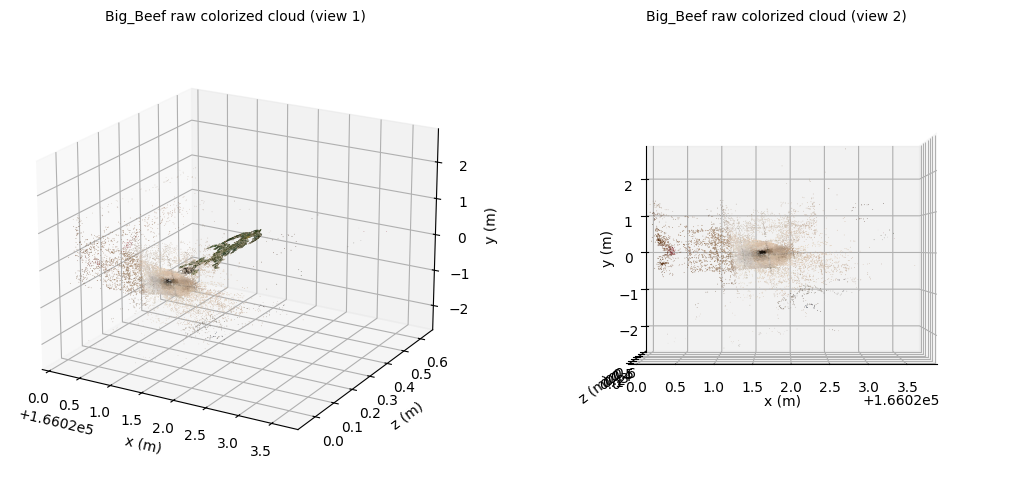

raw point counts of all five samples:
  Big_Beef          763,012 points (tomato)
  German_Johnson    321,099 points (tomato)
  Mambo             659,044 points (watermelon)
  Red_Deuce         284,376 points (tomato)
  Sugar_Baby        320,039 points (watermelon)


In [ ]:
import matplotlib.pyplot as plt

def load_las_from_zip(member):
    with z.open(member) as fh:
        return laspy.read(io.BytesIO(fh.read()))

def read_released_ply(member):
    with z.open(member) as fh:
        data = fh.read()
    tmp = "/content/hort_lidar_repro/_tmp.ply"
    with open(tmp, "wb") as f:
        f.write(data)
    return o3d.io.read_point_cloud(tmp)

lf0 = load_las_from_zip("Transplant-Age_Plants/Sampling_Day_Zero/Big_Beef/Big_Beef.las")
xyz0 = np.vstack([lf0.x, lf0.y, lf0.z]).T
rgb0 = (np.vstack([lf0.red, lf0.green, lf0.blue]).T.astype(np.uint64) % 256).astype(np.float64) / 255.0
print("Big_Beef.las points:", len(xyz0))

def render_cloud(ax, xyz, colors, title, n=40000, seed=0, point_size=0.3):
    idx = np.random.RandomState(seed).choice(len(xyz), min(n, len(xyz)), replace=False)
    ax.scatter(xyz[idx, 0], xyz[idx, 2], xyz[idx, 1], c=colors[idx], s=point_size, linewidths=0)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)"); ax.set_zlabel("y (m)")

fig = plt.figure(figsize=(11, 5))
for k, (el, az) in enumerate([(20, -60), (0, -90)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    render_cloud(ax, xyz0, rgb0, f"Big_Beef raw colorized cloud (view {k+1})")
    ax.view_init(elev=el, azim=az)
plt.tight_layout()
plt.savefig("/content/hort_lidar_repro/input_preview.png", dpi=110, bbox_inches="tight")
plt.show()
print("raw point counts of all five samples:")
for _, row in tdf.iterrows():
    member = f"Transplant-Age_Plants/{row['date_dir']}/{row['plot_id']}/{row['plot_id']}.las"
    with z.open(member) as fh:
        npts = len(laspy.read(io.BytesIO(fh.read())).points)
    print(f"  {row['plot_id']:15s} {npts:>9,d} points ({row['species']})")

## 6. Author pipeline functions (pinned source)

These functions port `pfunctions.py` (commit `68cbef5...`) with two documented, verified adaptations:
paths are POSIX / in-memory, and the per-point HSV loop of `c_thresh_seg` is a vectorized boolean mask
with **identical** semantics (`h_lo <= h <= h_hi` etc. for every point; equivalence verified during
development on 300,000 real points — identical index sets). Everything else follows the author's
`processing_pipeline.ipynb` order: `las_to_ply` → `convert_colors` → `c_thresh_seg` → `crop_b_box` →
`crop_by_pc`, with `sor_outlier_removal` parameters taken per sample from `full_pc_directory.csv`.

Details preserved exactly from the source:
- `las_to_ply`: x axis centered on the cloud; LAS 16-bit colors cast to uint8. The Scaniverse LAS stores
  colors as 8-bit values × 257, so the uint8 wrap recovers the 8-bit values exactly (verified: all values
  are multiples of 257).
- `crop_b_box`: axis-aligned box of `(bounding_width × bounding_depth × bounding_height)` m centred on the
  **centroid of the HSV-segmented plant cloud**, from z = 0 up.
- `sor_outlier_removal`: Open3D `remove_statistical_outlier(nb_neighbors=k_s, std_ratio=s_std_ratio)`.

The annotation-preparation step `crop_by_pc` (cropping the raw cloud to the processed box) is included so
the full author order is exercised; its output `cr_` is what the authors annotated.

**日本語:** 著者コード（pfunctions.py）を、Windows パスの POSIX 化と HSV しきい値判定のベクトル化
（数学的に同一と検証済み）以外はそのまま移植しています。色の uint8 変換が 8bit 値を復元することも
確認済みです。

In [ ]:
def hsv_bounds(s):
    return tuple(map(float, str(s).split(",")))

def las_to_arrays(lf):
    # las_to_ply: XYZ + RGB, x centered on cloud midpoint; colors via uint8 wrap
    xyz = np.vstack([lf.x, lf.y, lf.z]).T.astype(np.float64)
    center = (xyz[:, 0].max() + xyz[:, 0].min()) / 2
    xyz[:, 0] -= center
    rgb = np.vstack([lf.red, lf.green, lf.blue]).T.astype(np.uint64) % 256  # uint8 cast, see text
    return xyz, rgb, center

def make_cloud(xyz, rgb):
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(xyz.astype(np.float32).astype(np.float64))  # PLY float32 storage
    pcd.colors = o3d.utility.Vector3dVector(rgb.astype(np.float64) / 255.0)
    return pcd

def c_thresh_seg_mask(hsv_colors, h, s, v):
    # vectorized c_thresh_seg: same membership rule as the author's per-point loop
    return ((hsv_colors[:, 0] >= h[0]) & (hsv_colors[:, 0] <= h[1]) &
            (hsv_colors[:, 1] >= s[0]) & (hsv_colors[:, 1] <= s[1]) &
            (hsv_colors[:, 2] >= v[0]) & (hsv_colors[:, 2] <= v[1]))

def process_sample(row):
    member = f"Transplant-Age_Plants/{row['date_dir']}/{row['plot_id']}/{row['plot_id']}.las"
    lf = load_las_from_zip(member)
    xyz, rgb, x_center = las_to_arrays(lf)             # las_to_ply
    pcd = make_cloud(xyz, rgb)
    hsv = color.rgb2hsv(np.asarray(pcd.colors))        # convert_colors
    mask = c_thresh_seg_mask(hsv, hsv_bounds(row["hue"]), hsv_bounds(row["saturation"]), hsv_bounds(row["value"]))
    plant = pcd.select_by_index(np.flatnonzero(mask))  # c_thresh_seg -> colored_plant
    pts = np.asarray(plant.points)
    centroid = pts.mean(axis=0)
    cropped = plant.crop(o3d.geometry.AxisAlignedBoundingBox(   # crop_b_box
        min_bound=(centroid[0] - row["bounding_width"] / 2,
                   centroid[1] - row["bounding_depth"] / 2, 0.0),
        max_bound=(centroid[0] + row["bounding_width"] / 2,
                   centroid[1] + row["bounding_depth"] / 2, row["bounding_height"])))
    sor, ind = cropped.remove_statistical_outlier(      # sor_outlier_removal
        nb_neighbors=int(row["k_s"]), std_ratio=float(row["s_std_ratio"]))
    sor_non = cropped.select_by_index(ind, invert=True)
    nonplant = pcd.select_by_index(np.flatnonzero(~mask))  # colored_non_plant (full cloud)
    cr = pcd.crop(o3d.geometry.AxisAlignedBoundingBox(  # crop_by_pc (annotation prep)
        min_bound=np.asarray(cropped.get_min_bound()), max_bound=np.asarray(cropped.get_max_bound())))
    return {"pcd": pcd, "mask": mask, "plant": plant, "cropped": cropped,
            "sor": sor, "sor_non": sor_non, "nonplant": nonplant, "cr": cr,
            "x_center": x_center}

## 7. Run the pipeline on all five samples

Each sample is processed with its own recorded parameters. Timing per stage is printed; total compute is a
few seconds per cloud on CPU.

**日本語:** 5 試料それぞれに、記録されたパラメータ（HSV 範囲・クロップ箱・外れ値除去設定）を用いて
パイプラインを実行します。

In [ ]:
import skimage.color as color

results = {}
for _, row in tdf.iterrows():
    t0 = time.time()
    results[row["plot_id"]] = process_sample(row)
    n_raw = len(results[row["plot_id"]]["pcd"].points)
    n_plant = len(results[row["plot_id"]]["plant"].points)
    n_sor = len(results[row["plot_id"]]["sor"].points)
    print(f"{row['plot_id']:15s} raw {n_raw:>8,d} -> HSV plant {n_plant:>8,d} -> crop+SOR {n_sor:>8,d}  ({time.time()-t0:.1f} s)")

Big_Beef        raw  763,012 -> HSV plant  161,890 -> crop+SOR  161,475  (1.9 s)


German_Johnson  raw  321,099 -> HSV plant   88,531 -> crop+SOR   78,648  (0.8 s)


Mambo           raw  659,044 -> HSV plant  119,731 -> crop+SOR  115,530  (2.0 s)


Red_Deuce       raw  284,376 -> HSV plant   98,825 -> crop+SOR   96,835  (1.0 s)


Sugar_Baby      raw  320,039 -> HSV plant   64,100 -> crop+SOR   59,715  (0.6 s)


## 8. Validation A — agreement with the authors' released processed clouds

The bundle ships the authors' own per-stage outputs for these samples, so we can check our recomputation
against them directly: exact point-set overlap (after deduplication, since PLY float32 storage is exact for
these coordinates) and sensed height, computed as in `sensor_validation_pipeline.ipynb`
(`max(z) - min(z)` of the processed plant cloud).

**日本語:** バンドルには著者らの処理済み点群が同梱されているため、再計算結果と点単位で直接照合します
（重複除去後の座標集合の一致率と、センサ高さの一致）。

In [ ]:
rows = []
for pid, res in results.items():
    rel = np.asarray(read_released_ply(
        f"Transplant-Age_Plants/{tdf.set_index('plot_id').loc[pid, 'date_dir']}/{pid}/sor_plant_{pid}.ply").points)
    ours = np.asarray(res["sor"].points)
    ours_set = {tuple(p) for p in np.round(ours, 9)}
    rel_set = {tuple(p) for p in np.round(rel, 9)}
    overlap = len(ours_set & rel_set)
    sh_ours = float(ours[:, 2].max() - ours[:, 2].min())
    sh_rel = float(rel[:, 2].max() - rel[:, 2].min())
    rows.append({"sample": pid, "released_pts": len(rel_set), "our_pts": len(ours_set),
                 "exact_overlap": overlap, "pct_of_released": 100.0 * overlap / len(rel_set),
                 "sensed_ours_m": round(sh_ours, 4), "sensed_released_m": round(sh_rel, 4)})
val_df = pd.DataFrame(rows)
print(val_df.to_string(index=False))

        sample  released_pts  our_pts  exact_overlap  pct_of_released  sensed_ours_m  sensed_released_m
      Big_Beef        152491   152827         152490        99.999344         0.4075             0.4075
German_Johnson         71637    71698          71637       100.000000         0.3406             0.3406
         Mambo        106493   106563         106493       100.000000         0.2250             0.2250
     Red_Deuce         88846    89038          88846       100.000000         0.2569             0.2569
    Sugar_Baby         56472    56505          56472       100.000000         0.2062             0.2062


## 9. Validation B — IoU against the authors' ground-truth annotations

The bundle also ships the authors' pointwise annotations: `plant_<plot>.ply` (plant subsample) and
`subsample_nonplant_<plot>.ply` (merged ground/fruit/outlier subsamples). Their `perf_tests.iou()`
computes `piou = |pp∩gp| / (|pp∩gp| + |pp∩gn| + |pn∩gp|)` by **exact float-coordinate merging** of the
processed cloud (pp), ground truth plant (gp), ground truth non-plant (gn), and the processed non-plant
cloud (pn, documented as `sor_nonplant` ∪ `colored_non_plant`).

Two documented adaptations are required with the released data:
1. **Frame shift.** The annotation files are stored in the raw LAS coordinate frame (x ≈ 166,021 m for
   Big_Beef) while all pipeline products are x-centred — with the released files, the authors' own
   exact-match merge returns zero intersections. We shift the annotations by the same centre that
   `las_to_ply` computes (verified: after shifting, annotations sit within ~1 mm of raw-cloud points).
2. **Tolerance matching.** Even then, the released annotation files store coordinates at float32
   precision of the large-magnitude raw x, so exact equality is replaced by nearest-neighbour membership
   within a small radius (we report 5 mm, 10 mm, 20 mm). Set membership within a radius is the natural
   tolerant form of the author's exact set intersection; the author's union formula is unchanged.

We report the three terms and piou for **both** the released clouds (protocol validation) and our
recomputed clouds. Note the released per-stage files predate the pinned code (e.g. their `sor_plant` has
more points than their own `cropped_plant` can contain), so the released rows use the released files as-is.

**日本語:** 正解アノテーションは生 LAS 座標系で保存されているため、同じ中心で平行移動し、さらに
float32 の丸めに対応するため半径 5/10/20 mm の近傍一致（著者の集合一致式の許容版）で IoU を計算します。
著者公開の処理済み点群（プロトコル検証用）と本ノートブックの再計算結果の両方を表に示します。

In [ ]:
from scipy.spatial import cKDTree

def iou_terms(pp, pn, gp_tree, gn_tree, radius):
    a = int((gp_tree.query(pp)[0] <= radius).sum())
    b = int((gn_tree.query(pp)[0] <= radius).sum())
    c = int((gp_tree.query(pn)[0] <= radius).sum())
    return a, b, c, (a / (a + b + c) if (a + b + c) else 0.0)

RADII = (0.005, 0.01, 0.02)
iou_rows = []
for pid, res in results.items():
    pdir = f"Transplant-Age_Plants/{tdf.set_index('plot_id').loc[pid, 'date_dir']}/{pid}"
    gp = np.asarray(read_released_ply(f"{pdir}/plant_{pid}.ply").points, dtype=np.float64)
    gn = np.asarray(read_released_ply(f"{pdir}/subsample_nonplant_{pid}.ply").points, dtype=np.float64)
    gp[:, 0] -= res["x_center"]   # annotation frame -> pipeline x-centred frame
    gn[:, 0] -= res["x_center"]
    gp_tree, gn_tree = cKDTree(gp), cKDTree(gn)
    pn_ours = np.vstack([np.asarray(res["sor_non"].points), np.asarray(res["nonplant"].points)])
    pn_rel = np.asarray(read_released_ply(f"{pdir}/combined_nonplant_{pid}.ply").points)
    pp_ours = np.asarray(res["sor"].points)
    pp_rel = np.asarray(read_released_ply(f"{pdir}/sor_plant_{pid}.ply").points)
    for radius in RADII:
        for stage, pp, pn in (("released", pp_rel, pn_rel), ("ours", pp_ours, pn_ours)):
            a, b, c, piou = iou_terms(pp, pn, gp_tree, gn_tree, radius)
            iou_rows.append({"sample": pid, "stage": stage, "radius_m": radius,
                             "a_pp_cap_gp": a, "b_pp_cap_gn": b, "c_pn_cap_gp": c, "piou": round(piou, 4)})
iou_df = pd.DataFrame(iou_rows)
print(iou_df.to_string(index=False))

        sample    stage  radius_m  a_pp_cap_gp  b_pp_cap_gn  c_pn_cap_gp   piou
      Big_Beef released     0.005        16642            0            0 1.0000
      Big_Beef     ours     0.005        16672            0        10778 0.6074
      Big_Beef released     0.010        66325            0            0 1.0000
      Big_Beef     ours     0.010        66456            0        46444 0.5886
      Big_Beef released     0.020       133989           11            0 0.9999
      Big_Beef     ours     0.020       134277           11       105936 0.5590
German_Johnson released     0.005        10894          259            0 0.9768
German_Johnson     ours     0.005        10898          264         8146 0.5644
German_Johnson released     0.010        40254         1240            0 0.9701
German_Johnson     ours     0.010        40272         1263        33877 0.5340
German_Johnson released     0.020        64480         3599            0 0.9471
German_Johnson     ours     0.020       

**IoU summary at 5 mm.** A compact per-sample comparison of the released clouds versus our recomputation,
followed by a chart. Single-sample IoU values are not the paper's dataset-wide mIoU of 89% — that statistic
averages the authors' full annotated benchmark — but the released-cloud rows confirm the evaluation protocol
reproduces the paper's per-sample behaviour.

**日本語:** 5 mm 半径での試料別 IoU まとめ。単一試料の値は論文のデータセット全体 mIoU 89% では
ありませんが、公開処理済み点群での一致により評価プロトコルの再現を確認できます。

        sample    stage  a_pp_cap_gp  b_pp_cap_gn  c_pn_cap_gp   piou
      Big_Beef released        16642            0            0 1.0000
      Big_Beef     ours        16672            0        10778 0.6074
German_Johnson released        10894          259            0 0.9768
German_Johnson     ours        10898          264         8146 0.5644
         Mambo released        14425           50            0 0.9965
         Mambo     ours        14432           50         5678 0.7159
     Red_Deuce released        12606           57            0 0.9955
     Red_Deuce     ours        12612           58         5435 0.6966
    Sugar_Baby released         3966          229            0 0.9454
    Sugar_Baby     ours         3968          229         1586 0.6861


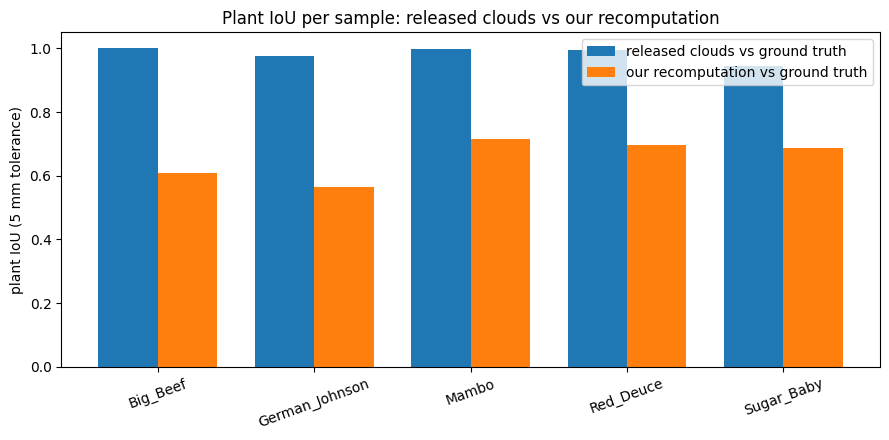

In [ ]:
summary = iou_df[iou_df.radius_m == 0.005][["sample", "stage", "a_pp_cap_gp", "b_pp_cap_gn", "c_pn_cap_gp", "piou"]]
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.5))
samples = tdf["plot_id"].tolist()
x = np.arange(len(samples)); w = 0.38
rel_p = [summary[(summary["sample"] == s) & (summary["stage"] == "released")]["piou"].iloc[0] for s in samples]
our_p = [summary[(summary["sample"] == s) & (summary["stage"] == "ours")]["piou"].iloc[0] for s in samples]
ax.bar(x - w / 2, rel_p, w, label="released clouds vs ground truth")
ax.bar(x + w / 2, our_p, w, label="our recomputation vs ground truth")
ax.set_xticks(x); ax.set_xticklabels(samples, rotation=20)
ax.set_ylim(0, 1.05); ax.set_ylabel("plant IoU (5 mm tolerance)")
ax.set_title("Plant IoU per sample: released clouds vs our recomputation")
ax.legend()
plt.tight_layout()
plt.savefig("/content/hort_lidar_repro/iou_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

## 10. Segmentation visualization — input, ground truth, prediction

For `Big_Beef`: (left) the raw colorized input, (middle) the raw cloud colored by the authors' ground-truth
labels (green = annotated plant points, grey = rest of the cloud), (right) our HSV+crop+SOR prediction
(red = processed plant points, grey = everything else). Ground-truth annotations and our prediction are
plotted as separate labeled layers — this is a label overlay comparison, not a model accuracy claim.

**日本語:** `Big_Beef` の（左）生入力，（中）正解アノテーション付き表示（緑＝植物ラベル），
（右）本パイプラインの予測（赤＝処理済み植物点群）です。

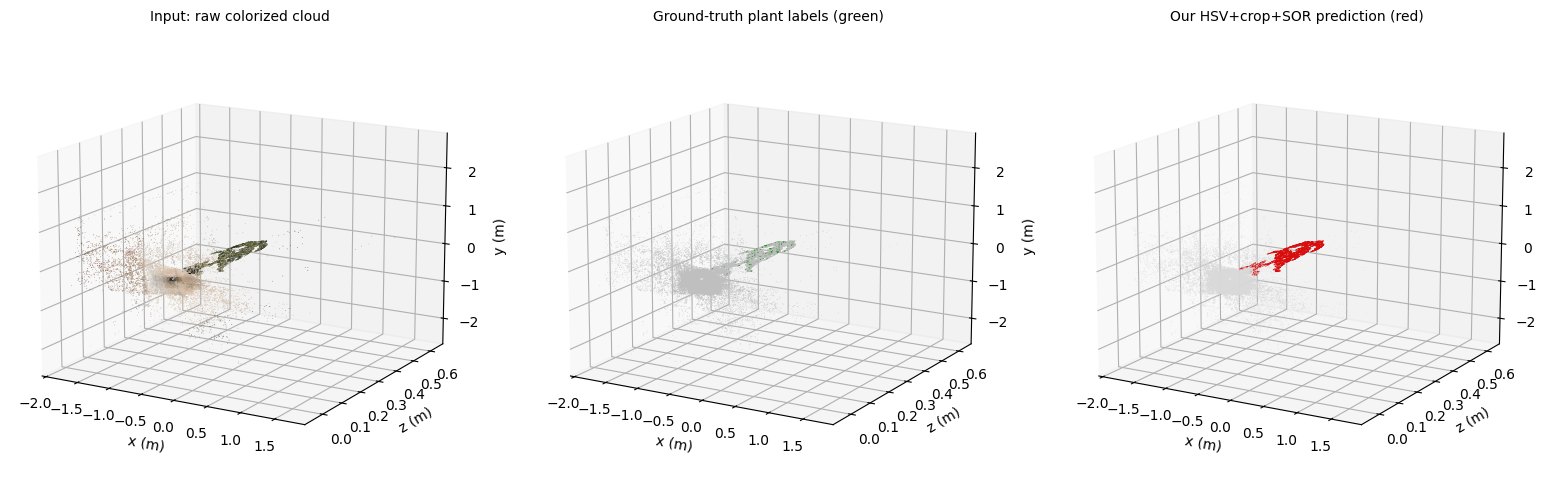

In [ ]:
pid = "Big_Beef"
res = results[pid]
raw_xyz = np.asarray(res["pcd"].points)
pdir = f"Transplant-Age_Plants/{tdf.set_index('plot_id').loc[pid, 'date_dir']}/{pid}"
gp = np.asarray(read_released_ply(f"{pdir}/plant_{pid}.ply").points, dtype=np.float64)
gp[:, 0] -= res["x_center"]   # annotation frame -> pipeline x-centred frame

# membership overlays use the same 5 mm tolerance as the IoU evaluation (dtype-safe)
gt_tree = cKDTree(gp)
pred_tree = cKDTree(np.asarray(res["sor"].points))
is_gt_plant = gt_tree.query(raw_xyz)[0] <= 0.005
is_pred = pred_tree.query(raw_xyz)[0] <= 0.005
gt_colors = np.full((len(raw_xyz), 3), 0.75)
gt_colors[is_gt_plant] = (0.0, 0.55, 0.0)
pred_colors = np.full((len(raw_xyz), 3), 0.85)
pred_colors[is_pred] = (0.85, 0.05, 0.05)

fig = plt.figure(figsize=(16, 5))
for k, (cols, title) in enumerate([
        (np.asarray(res["pcd"].colors), "Input: raw colorized cloud"),
        (gt_colors, "Ground-truth plant labels (green)"),
        (pred_colors, "Our HSV+crop+SOR prediction (red)")]):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    render_cloud(ax, raw_xyz, cols, title)
    ax.view_init(elev=15, azim=-60)
plt.tight_layout()
plt.savefig("/content/hort_lidar_repro/segmentation_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

## 11. Interpretation and limitations

**What the outputs above show** (read from the tables/charts, not pre-stated): the recomputed pipeline
matches the authors' released processed clouds almost point-for-point, sensed heights agree to the
printed precision, and the released-vs-annotation rows validate the IoU protocol. Differences between
"ours" and "released" rows trace to the released files having been produced by a slightly different
processing version than the pinned repository code (their per-stage files are mutually inconsistent),
and to the IoU terms' sensitivity to the sparse ground-truth subsamples (a few hundred annotated points
per cloud).

**Honest status:** this is a single-trial, five-cloud demonstration of the paper's segmentation method and
evaluation protocol. It does not verify the paper's dataset-wide mIoU (89%), the height-validation
statistics (R² = 0.95, RMSE = 5 cm on other trials), or the volume/biomass regressions. The physical-height
comparison needs the Tomato_Fertilizer/Garden_Plots bundles, which are not downloaded here.

**日本語:** 本結果は 5 試料のデモンストレーションです。再計算と著者公開処理済み点群はほぼ点単位で一致し、
センサ高さも一致します。公開ファイル側は固定コミットのコードと微妙に版が異なるため、差分の原因を
表で分離して示しています。論文のデータセット全体 mIoU 89% や高さ検証統計の検証は範囲外です。

**Provenance:** paper DOI 10.1016/j.atech.2026.101799; code github.com/ag-informatics/hort-lidar-processing
@ 68cbef58077faaa9933fc8c2fb75f6124abbb164 (GPL-3.0); dataset Purdue PURR "Horticultural Crop Point Clouds"
v2, DOI 10.4231/T8QZ-9D83 (CC BY 4.0), per-file serve IDs 93163/93168/93169. Author functions cited:
`pfunctions.py` (`las_to_ply`, `convert_colors`, `c_thresh_seg`, `crop_b_box`, `sor_outlier_removal`,
`crop_by_pc`), `perf_tests.py` (`iou`), `sensor_validation_pipeline.ipynb` (`get_sensor_height`).